In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [6]:
# Load the dataset
df = pd.read_csv(r'C:\Users\DELL\Downloads\amazon_sales_dataset.csv')

# Display first 5 rows
df.head()

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue
0,1,2022-04-13,2637,Books,128.75,10,4,North America,UPI,3.5,443,115.88,463.52
1,2,2023-03-12,2300,Fashion,302.60,20,5,Asia,Credit Card,3.7,475,242.08,1210.40
2,3,2022-09-28,3670,Sports,495.80,20,2,Europe,UPI,4.4,183,396.64,793.28
3,4,2022-04-17,2522,Books,371.95,15,4,Middle East,UPI,5.0,212,316.16,1264.64
4,5,2022-03-13,1717,Beauty,201.68,0,4,Middle East,UPI,4.6,308,201.68,806.72


In [7]:
print(df.shape)

(50000, 13)


In [8]:
print(df.columns.tolist())

['order_id', 'order_date', 'product_id', 'product_category', 'price', 'discount_percent', 'quantity_sold', 'customer_region', 'payment_method', 'rating', 'review_count', 'discounted_price', 'total_revenue']


In [9]:
print(df.dtypes)

order_id              int64
order_date           object
product_id            int64
product_category     object
price               float64
discount_percent      int64
quantity_sold         int64
customer_region      object
payment_method       object
rating              float64
review_count          int64
discounted_price    float64
total_revenue       float64
dtype: object


In [10]:
print(df.head())

   order_id  order_date  product_id product_category   price  \
0         1  2022-04-13        2637            Books  128.75   
1         2  2023-03-12        2300          Fashion  302.60   
2         3  2022-09-28        3670           Sports  495.80   
3         4  2022-04-17        2522            Books  371.95   
4         5  2022-03-13        1717           Beauty  201.68   

   discount_percent  quantity_sold customer_region payment_method  rating  \
0                10              4   North America            UPI     3.5   
1                20              5            Asia    Credit Card     3.7   
2                20              2          Europe            UPI     4.4   
3                15              4     Middle East            UPI     5.0   
4                 0              4     Middle East            UPI     4.6   

   review_count  discounted_price  total_revenue  
0           443            115.88         463.52  
1           475            242.08        1210.40  

In [11]:
print(df.tail())

       order_id  order_date  product_id product_category   price  \
49995     49996  2022-09-03        1433           Beauty   26.99   
49996     49997  2022-07-03        1428           Beauty  294.23   
49997     49998  2023-02-17        4651      Electronics  352.11   
49998     49999  2022-09-30        4371           Beauty  307.54   
49999     50000  2023-06-29        2944   Home & Kitchen  253.44   

       discount_percent  quantity_sold customer_region payment_method  rating  \
49995                 0              5     Middle East    Credit Card     2.4   
49996                10              5            Asia    Credit Card     3.1   
49997                30              4            Asia     Debit Card     3.1   
49998                 5              1     Middle East            UPI     1.8   
49999                30              1          Europe     Debit Card     2.1   

       review_count  discounted_price  total_revenue  
49995           386             26.99         134

In [12]:
print(df.isnull().sum())

order_id            0
order_date          0
product_id          0
product_category    0
price               0
discount_percent    0
quantity_sold       0
customer_region     0
payment_method      0
rating              0
review_count        0
discounted_price    0
total_revenue       0
dtype: int64


In [13]:
print(df.duplicated().sum())

0


In [14]:
df['order_date'] = pd.to_datetime(df['order_date'])
print(df['order_date'].dtype)

datetime64[ns]


In [15]:
df['month'] = df['order_date'].dt.month
df['year'] = df['order_date'].dt.year
print(df[['order_date', 'month', 'year']].head())

  order_date  month  year
0 2022-04-13      4  2022
1 2023-03-12      3  2023
2 2022-09-28      9  2022
3 2022-04-17      4  2022
4 2022-03-13      3  2022


In [16]:
print("Total Revenue:", df['total_revenue'].sum())
print("Total Quantity Sold:", df['quantity_sold'].sum())
print("Average Price:", df['price'].mean())

Total Revenue: 32866573.740000002
Total Quantity Sold: 149970
Average Price: 252.50726


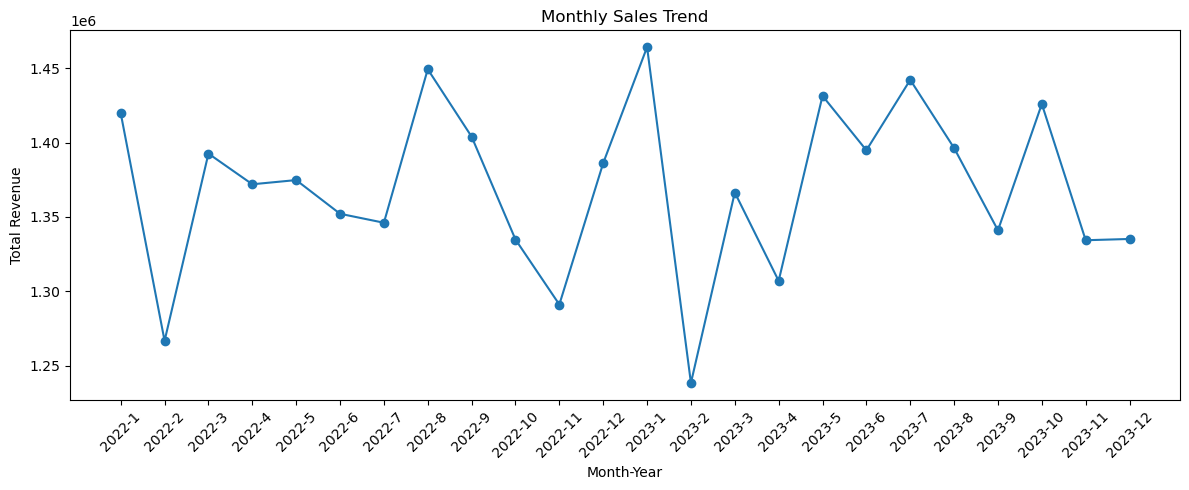

In [17]:
monthly_sales = df.groupby(['year', 'month'])['total_revenue'].sum().reset_index()

plt.figure(figsize=(12, 5))
plt.plot(range(len(monthly_sales)), monthly_sales['total_revenue'], marker='o')
plt.xticks(range(len(monthly_sales)), [f"{int(r['year'])}-{int(r['month'])}" for _, r in monthly_sales.iterrows()], rotation=45)
plt.title('Monthly Sales Trend')
plt.xlabel('Month-Year')
plt.ylabel('Total Revenue')
plt.tight_layout()
plt.show()

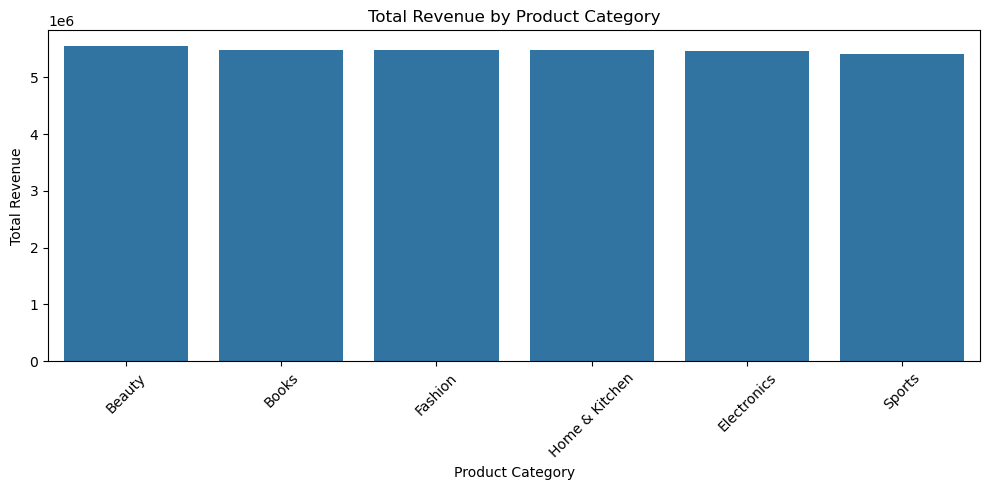

In [18]:
category_performance = df.groupby('product_category')['total_revenue'].sum().reset_index()
category_performance = category_performance.sort_values('total_revenue', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='product_category', y='total_revenue', data=category_performance)
plt.title('Total Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

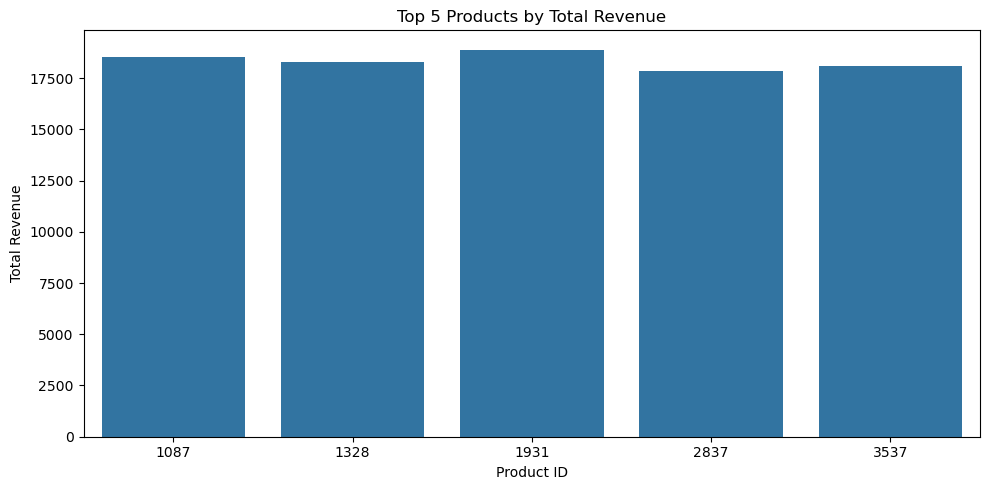

In [19]:
top_products = df.groupby('product_id')['total_revenue'].sum().reset_index()
top_products = top_products.sort_values('total_revenue', ascending=False).head(5)

plt.figure(figsize=(10, 5))
sns.barplot(x='product_id', y='total_revenue', data=top_products)
plt.title('Top 5 Products by Total Revenue')
plt.xlabel('Product ID')
plt.ylabel('Total Revenue')
plt.tight_layout()
plt.show()

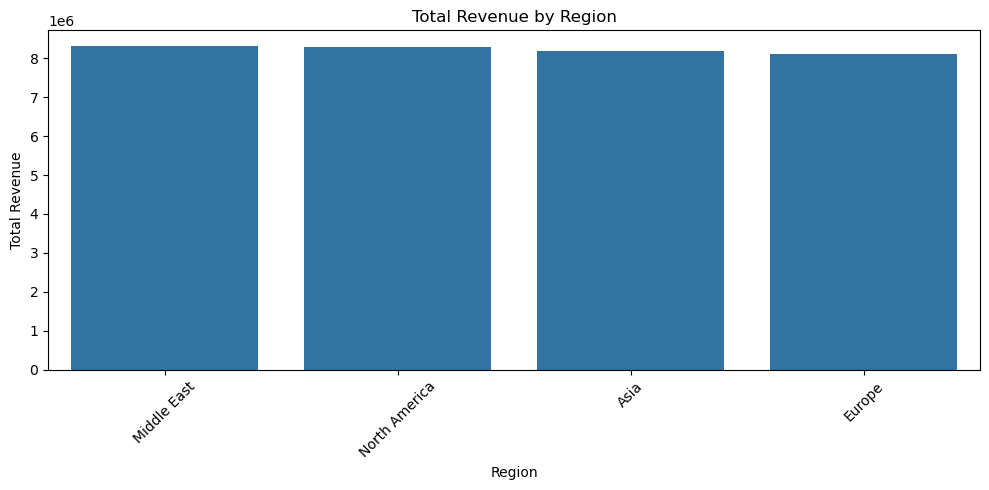

In [20]:
regional_performance = df.groupby('customer_region')['total_revenue'].sum().reset_index()
regional_performance = regional_performance.sort_values('total_revenue', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='customer_region', y='total_revenue', data=regional_performance)
plt.title('Total Revenue by Region')
plt.xlabel('Region')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
print(regional_performance)

  customer_region  total_revenue
2     Middle East     8301844.50
3   North America     8277217.84
0            Asia     8175199.83
1          Europe     8112311.57


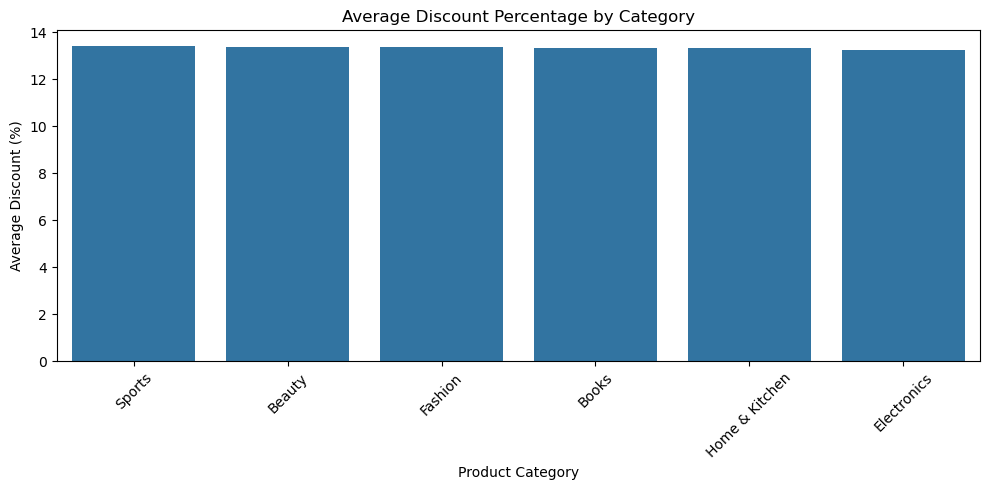

In [22]:
category_discount = df.groupby('product_category')['discount_percent'].mean().reset_index()
category_discount = category_discount.sort_values('discount_percent', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='product_category', y='discount_percent', data=category_discount)
plt.title('Average Discount Percentage by Category')
plt.xlabel('Product Category')
plt.ylabel('Average Discount (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
print(category_discount)

  product_category  discount_percent
5           Sports         13.406534
0           Beauty         13.371530
3          Fashion         13.358637
1            Books         13.337336
4   Home & Kitchen         13.311334
2      Electronics         13.258413


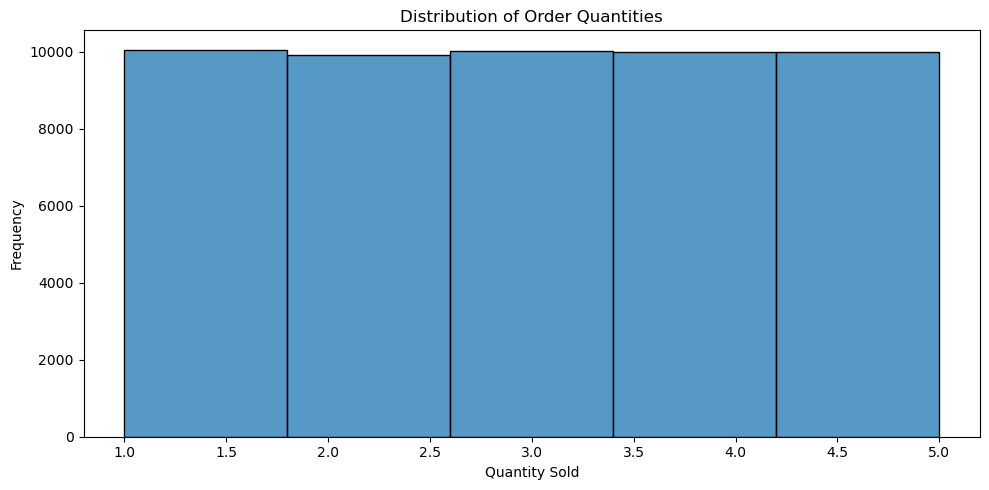

In [24]:
plt.figure(figsize=(10, 5))
sns.histplot(df['quantity_sold'], bins=5)
plt.title('Distribution of Order Quantities')
plt.xlabel('Quantity Sold')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [25]:
print(df['quantity_sold'].value_counts().sort_index())

quantity_sold
1    10060
2     9914
3    10026
4     9996
5    10004
Name: count, dtype: int64


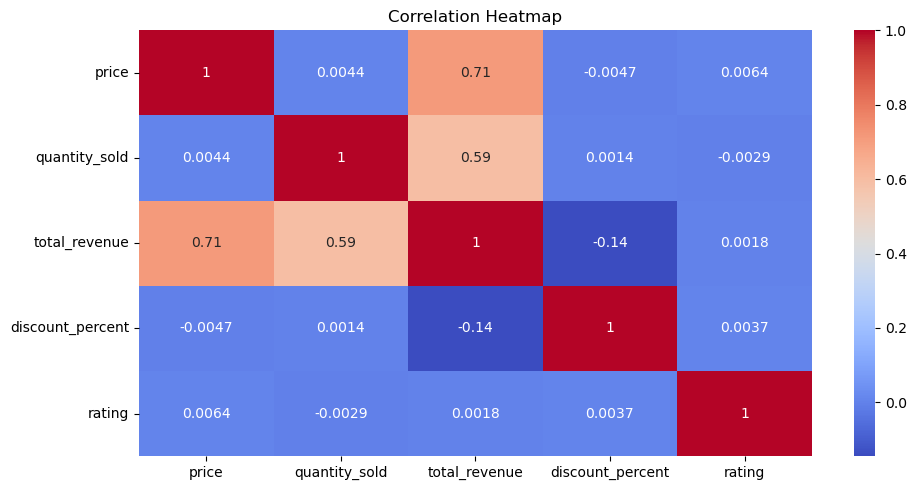

In [26]:
plt.figure(figsize=(10, 5))
sns.heatmap(df[['price', 'quantity_sold', 'total_revenue', 'discount_percent', 'rating']].corr(), 
            annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()